# 💳 FDS 최종 리포트 — Test Set 평가 & SHAP(XAI)

- **목적**: 검증(Validation) 단계에서 고정한 모델·임계값을 **Test Set에 단 한 번** 적용하여 최종 성능을 보고하고, SHAP으로 사기 판단 근거를 설명합니다.
- **선행 노트북**: `eda_and_split.ipynb` → `baseline_evaluation.ipynb` → `supervised_modeling.ipynb`
- **원칙**
  - 모델 하이퍼파라미터와 임계값은 `supervised_modeling.ipynb`의 검증 결과(`reports/tables/supervised_val_candidates.csv`)를 그대로 사용합니다.
  - Test 결과를 보고 임계값·모델을 다시 고르지 않습니다. (Test 기준 시뮬레이션은 참고용)
  - 학습은 Train 데이터만 사용합니다.

## 1. 환경 설정 및 데이터 로드

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 프로젝트 최상위 폴더 (이 노트북은 experiments 폴더에서 실행)
PROJECT_ROOT = Path.cwd().parent

# 공통 함수가 있는 src 폴더를 파이썬 검색 경로에 추가
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from utils import (
    load_and_preprocess_data,
    evaluate_fds_model,
    evaluate_thresholds,
    plot_and_save_simulation,
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"          # 결과표(CSV) 저장 위치
TABLE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# SHAP 그래프는 유니코드 마이너스(−)를 쓰는데 나눔고딕에 없으므로 DejaVu Sans로 대체 표시
plt.rcParams["font.family"] = ["NanumGothic", "DejaVu Sans"]

print("사용 중인 파이썬:", sys.executable)
print("프로젝트 폴더:", PROJECT_ROOT)

사용 중인 파이썬: /home/user1/anaconda3/envs/dkenv/bin/python3.10
프로젝트 폴더: /home/user1/study/credit-card-fds


In [2]:
# Train / Validation은 공통 함수로 로드 (Time 컬럼 제거 규칙 동일 적용)
X_train, y_train, X_val, y_val = load_and_preprocess_data(DATA_DIR)

# Test는 공통 함수가 반환하지 않으므로 같은 규칙으로 직접 로드
test_df = pd.read_csv(DATA_DIR / "test_processed.csv")
X_test = test_df.drop(columns=["Class"])
X_test = X_test.drop(columns=[c for c in ["Time"] if c in X_test.columns])
y_test = test_df["Class"].values

# 학습 때와 컬럼 순서가 다르면 모델 입력이 어긋나므로 반드시 확인
assert list(X_test.columns) == list(X_train.columns), "Train/Test 컬럼 순서가 다릅니다."

print("Test 데이터:", X_test.shape)
print(f"Test 사기 거래: {y_test.sum()}건 ({y_test.mean():.4%})")

[Data Loaded] Train: (198621, 30), Validation: (42562, 30)


Test 데이터: (42562, 30)
Test 사기 거래: 74건 (0.1739%)


## 2. 검증 단계에서 확정한 모델·임계값 불러오기

`supervised_modeling.ipynb`의 선택 기준: **Recall ≥ 0.80인 임계값 후보 중 총 검토 건수(TP+FP)가 가장 적은 것**

In [3]:
candidates = pd.read_csv(TABLE_DIR / "supervised_val_candidates.csv", encoding="utf-8-sig")

display(candidates[[
    "Model", "Threshold", "Recall", "Precision",
    "TP (사기 탐지)", "FP (오탐/검토 대상)", "FN (놓친 사기)", "Total Flagged (총 경고)",
]])

# 모델별 검증 확정 임계값
SELECTED_THRESHOLDS = dict(zip(candidates["Model"], candidates["Threshold"]))

# 최종 모델: 검증 기준 총 검토 건수가 가장 적은 모델
FINAL_MODEL_NAME = candidates.sort_values(
    ["Total Flagged (총 경고)", "Recall"], ascending=[True, False]
).iloc[0]["Model"]

print("모델별 확정 임계값:", SELECTED_THRESHOLDS)
print("최종 선택 모델:", FINAL_MODEL_NAME)

,Model,Threshold,Recall,Precision,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고)
0,RandomForest,0.05,0.864865,0.711111,64,26,10,90
1,XGBoost,0.30,0.810811,0.631579,60,35,14,95


모델별 확정 임계값: {'RandomForest': 0.05, 'XGBoost': 0.3}
최종 선택 모델: RandomForest


## 3. 모델 재학습 (Train 데이터만 사용)

`supervised_modeling.ipynb`에서 모델 파일을 저장하지 않았으므로 **동일한 하이퍼파라미터와 random_state**로 다시 학습합니다.
재학습 결과가 기존과 같은지 검증 PR-AUC를 저장된 값과 비교해 확인합니다.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# 랜덤포레스트: supervised_modeling.ipynb와 동일 설정
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# XGBoost: 학습 데이터 기준 정상/사기 비율로 가중치 계산 (동일 설정)
pos_weight = int((y_train == 0).sum()) / int((y_train == 1).sum())
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# 베이스라인 비교용 로지스틱 회귀: baseline_evaluation.ipynb와 동일 설정
lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, solver="lbfgs")

models = {"RandomForest": rf_model, "XGBoost": xgb_model, "LogisticRegression": lr_model}

for name, model in models.items():
    print(f"{name} 학습 중...")
    model.fit(X_train, y_train)
print("학습 완료!")

RandomForest 학습 중...


XGBoost 학습 중...


LogisticRegression 학습 중...


학습 완료!


In [5]:
from sklearn.metrics import average_precision_score

# 재학습한 모델의 검증 PR-AUC가 기존 결과와 일치하는지 확인 (재현성 점검)
saved_val = pd.read_csv(TABLE_DIR / "supervised_val_metrics.csv", encoding="utf-8-sig")
saved_val = dict(zip(saved_val["Model"], saved_val["PR_AUC"]))

for name in ["RandomForest", "XGBoost"]:
    val_ap = average_precision_score(y_val, models[name].predict_proba(X_val)[:, 1])
    match = "일치" if abs(val_ap - saved_val[name]) < 1e-3 else "불일치 ⚠ (라이브러리 버전 확인 필요)"
    print(f"{name:13s} 검증 PR-AUC 재학습 {val_ap:.5f} / 저장값 {saved_val[name]:.5f} → {match}")

RandomForest  검증 PR-AUC 재학습 0.83081 / 저장값 0.83081 → 일치
XGBoost       검증 PR-AUC 재학습 0.81256 / 저장값 0.81256 → 일치


## 4. Test Set 최종 평가

각 모델을 **기본 임계값 0.5**와 **검증에서 확정한 운영 임계값**으로 평가합니다.

In [6]:
# Test 데이터 사기 확률 (이후 시뮬레이션·SHAP에서 재사용)
test_probs = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}

test_results = []

# 베이스라인(로지스틱 회귀)은 기본 임계값 0.5로만 평가
lr_res = evaluate_fds_model(
    "LogisticRegression @0.5", y_test,
    (test_probs["LogisticRegression"] >= 0.5).astype(int), test_probs["LogisticRegression"],
)
lr_res.update({"Model": "LogisticRegression", "Threshold": 0.5, "Threshold_Type": "default"})
test_results.append(lr_res)

for name in ["RandomForest", "XGBoost"]:
    for th, th_type in [(0.5, "default"), (SELECTED_THRESHOLDS[name], "selected_on_validation")]:
        y_pred = (test_probs[name] >= th).astype(int)
        res = evaluate_fds_model(f"{name} @{th}", y_test, y_pred, test_probs[name])
        res.update({"Model": name, "Threshold": th, "Threshold_Type": th_type})
        test_results.append(res)

test_results_df = pd.DataFrame(test_results)
test_results_df["Total_Flagged"] = test_results_df["TP"] + test_results_df["FP"]
test_results_df["Split"] = "test"


================ [LogisticRegression @0.5] 평가 결과 ================
1. Accuracy  (정확도) : 0.99899
2. PR-AUC    (평균정밀도): 0.68035 ★
3. Recall    (재현율)  : 0.50000
4. Precision (정밀도)  : 0.86047
5. F1-Score  (조화평균): 0.63248
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42482     6]
 [   37    37]]
 - TN(정상 예측 성공): 42,482건 | FP(오탐 / 오인 신고): 6건 | FN(미탐 / 놓친 사기): 37건 | TP(사기 탐지 성공): 37건


================ [RandomForest @0.5] 평가 결과 ================
1. Accuracy  (정확도) : 0.99932
2. PR-AUC    (평균정밀도): 0.73640 ★
3. Recall    (재현율)  : 0.63514
4. Precision (정밀도)  : 0.95918
5. F1-Score  (조화평균): 0.76423
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42486     2]
 [   27    47]]
 - TN(정상 예측 성공): 42,486건 | FP(오탐 / 오인 신고): 2건 | FN(미탐 / 놓친 사기): 27건 | TP(사기 탐지 성공): 47건




================ [RandomForest @0.05] 평가 결과 ================
1. Accuracy  (정확도) : 0.99911
2. PR-AUC    (평균정밀도): 0.73640 ★
3. Recall    (재현율)  : 0.74324
4. Precision (정밀도)  : 0.74324
5. F1-Score  (조화평균): 0.74324
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42469    19]
 [   19    55]]
 - TN(정상 예측 성공): 42,469건 | FP(오탐 / 오인 신고): 19건 | FN(미탐 / 놓친 사기): 19건 | TP(사기 탐지 성공): 55건


================ [XGBoost @0.5] 평가 결과 ================
1. Accuracy  (정확도) : 0.99908
2. PR-AUC    (평균정밀도): 0.73320 ★
3. Recall    (재현율)  : 0.72973
4. Precision (정밀도)  : 0.73973
5. F1-Score  (조화평균): 0.73469
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42469    19]
 [   20    54]]
 - TN(정상 예측 성공): 42,469건 | FP(오탐 / 오인 신고): 19건 | FN(미탐 / 놓친 사기): 20건 | TP(사기 탐지 성공): 54건


================ [XGBoost @0.3] 평가 결과 ================
1. Accuracy  (정확도) : 0.99871
2. PR-AUC    (평균정밀도): 0.73320 ★
3. Recall    (재현율)  : 0.74324
4. Precision (정밀도)  : 0.6

### 4.1 검증 vs 테스트 비교 (운영 임계값 기준)

검증에서 기대한 성능이 테스트에서도 유지되는지 확인합니다. 사기 거래가 74건뿐이라 1건 차이가 Recall 약 1.35%p에 해당합니다.

In [7]:
val_th = pd.read_csv(TABLE_DIR / "supervised_val_thresholds.csv", encoding="utf-8-sig")

rows = []
for name in ["RandomForest", "XGBoost"]:
    th = SELECTED_THRESHOLDS[name]
    v = val_th[(val_th["Model"] == name) & np.isclose(val_th["Threshold"], th)].iloc[0]
    t = test_results_df[(test_results_df["Model"] == name) & np.isclose(test_results_df["Threshold"], th)].iloc[0]
    rows.append({
        "Model": name, "Threshold": th,
        "Val_Recall": v["Recall"], "Test_Recall": t["Recall"],
        "Val_Precision": v["Precision"], "Test_Precision": t["Precision"],
        "Val_Flagged": v["Total Flagged (총 경고)"], "Test_Flagged": t["Total_Flagged"],
        "Test_PR_AUC": t["PR_AUC"],
        "Recall_목표달성(≥0.80)": "O" if t["Recall"] >= 0.80 else "X",
    })

val_vs_test = pd.DataFrame(rows)
display(val_vs_test.round(4))

summary_cols = ["Model", "Threshold", "Threshold_Type", "PR_AUC", "Recall", "Precision",
                "F1_Score", "TP", "FP", "FN", "Total_Flagged"]
display(test_results_df[summary_cols].round(4))

,Model,Threshold,Val_Recall,Test_Recall,Val_Precision,Test_Precision,Val_Flagged,Test_Flagged,Test_PR_AUC,Recall_목표달성(≥0.80)
0,RandomForest,0.05,0.8649,0.7432,0.7111,0.7432,90,74,0.7364,X
1,XGBoost,0.30,0.8108,0.7432,0.6316,0.6044,95,91,0.7332,X


,Model,Threshold,Threshold_Type,PR_AUC,Recall,Precision,F1_Score,TP,FP,FN,Total_Flagged
0,LogisticRegression,0.50,default,0.6803,0.5000,0.8605,0.6325,37,6,37,43
1,RandomForest,0.50,default,0.7364,0.6351,0.9592,0.7642,47,2,27,49
2,RandomForest,0.05,selected_on_validation,0.7364,0.7432,0.7432,0.7432,55,19,19,74
3,XGBoost,0.50,default,0.7332,0.7297,0.7397,0.7347,54,19,20,73
4,XGBoost,0.30,selected_on_validation,0.7332,0.7432,0.6044,0.6667,55,36,19,91


### 4.2 PR 곡선 & 혼동행렬

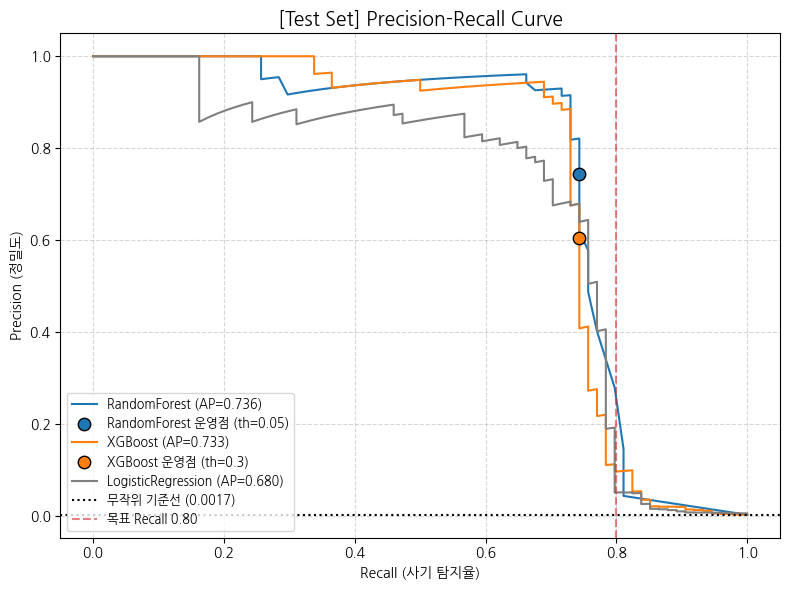

In [8]:
from sklearn.metrics import precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))

for name, color in [("RandomForest", "tab:blue"), ("XGBoost", "tab:orange"), ("LogisticRegression", "tab:gray")]:
    prec, rec, _ = precision_recall_curve(y_test, test_probs[name])
    ap = average_precision_score(y_test, test_probs[name])
    ax.plot(rec, prec, color=color, label=f"{name} (AP={ap:.3f})")

    # 운영 임계값 지점 표시
    if name in SELECTED_THRESHOLDS:
        th = SELECTED_THRESHOLDS[name]
        y_pred = (test_probs[name] >= th).astype(int)
        r = (y_pred[y_test == 1]).mean()
        p = y_test[y_pred == 1].mean()
        ax.scatter(r, p, color=color, s=80, edgecolor="black", zorder=5, label=f"{name} 운영점 (th={th})")

ax.axhline(y_test.mean(), color="black", linestyle=":", label=f"무작위 기준선 ({y_test.mean():.4f})")
ax.axvline(0.80, color="tab:red", linestyle="--", alpha=0.6, label="목표 Recall 0.80")
ax.set_xlabel("Recall (사기 탐지율)")
ax.set_ylabel("Precision (정밀도)")
ax.set_title("[Test Set] Precision-Recall Curve", fontsize=14)
ax.legend(loc="lower left", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "test_pr_curve.png", dpi=300)
plt.show()

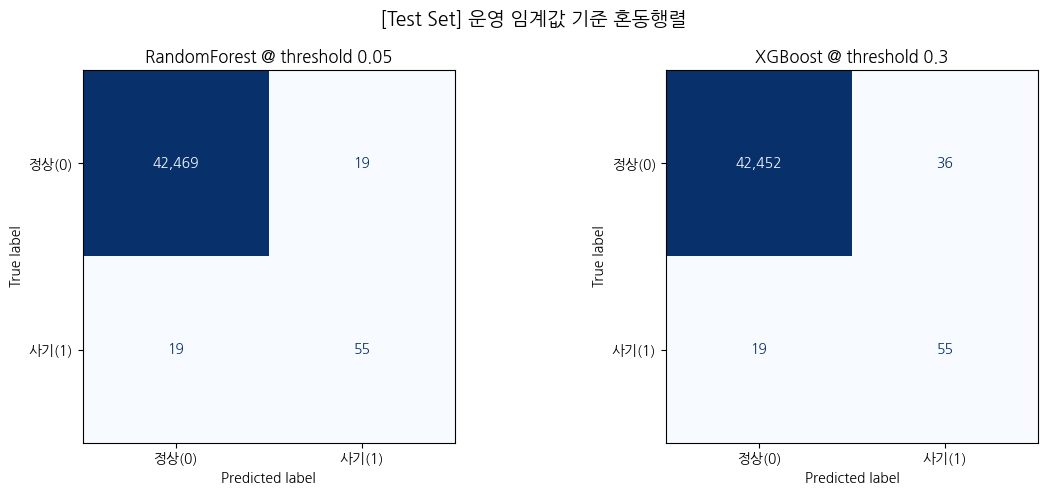

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, ["RandomForest", "XGBoost"]):
    th = SELECTED_THRESHOLDS[name]
    cm = confusion_matrix(y_test, (test_probs[name] >= th).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["정상(0)", "사기(1)"]).plot(
        ax=ax, cmap="Blues", values_format=",d", colorbar=False
    )
    ax.set_title(f"{name} @ threshold {th}")

plt.suptitle("[Test Set] 운영 임계값 기준 혼동행렬", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "test_confusion_matrix.png", dpi=300)
plt.show()

### 4.3 운영 비용 시뮬레이션

README의 총 손실 비용 계산식:

$$\text{총 손실 비용} = (\text{FN} \times \text{건당 사기 피해액}) + (\text{FP} \times \text{건당 검토 인건비})$$

- 처리된 데이터의 `Amount`는 스케일링되어 실제 금액을 알 수 없으므로 **건당 고정 비용 가정**을 사용합니다. 팀에서 합의한 값이 있으면 아래 상수만 바꾸면 됩니다.
- **하루 환산**: 원본 데이터는 약 48시간(2일)치이고 Test는 그중 무작위 15%입니다. 따라서 Test 건수 × (일일 거래량 / Test 건수)로 하루 기준 건수를 추정합니다.

In [10]:
# ---- 비용 가정 (팀 합의 시 수정) ----
FRAUD_LOSS_PER_CASE = 122.0   # 건당 사기 피해액 (EUR) : 원본 데이터 사기 거래 평균 금액(약 122 EUR) 참고
REVIEW_COST_PER_CASE = 5.0    # 건당 검토 인건비 (EUR) : 가정값

# ---- 하루 환산 계수 ----
TOTAL_ROWS = len(X_train) + len(X_val) + len(X_test)   # 전처리 후 전체 거래 수
DATA_DAYS = 2                                           # 원본 데이터 기간 (약 48시간)
DAILY_SCALE = (TOTAL_ROWS / DATA_DAYS) / len(X_test)    # Test 건수 → 하루 건수 환산 배율
print(f"하루 환산 배율: {DAILY_SCALE:.2f} (Test {len(X_test):,}건 ≈ 하루 거래의 {1 / DAILY_SCALE:.1%})")

cost_df = test_results_df[summary_cols].copy()
cost_df["Fraud_Loss"] = cost_df["FN"] * FRAUD_LOSS_PER_CASE
cost_df["Review_Cost"] = cost_df["FP"] * REVIEW_COST_PER_CASE
cost_df["Total_Cost"] = cost_df["Fraud_Loss"] + cost_df["Review_Cost"]
cost_df["Daily_Flagged_Est"] = (cost_df["Total_Flagged"] * DAILY_SCALE).round().astype(int)
cost_df["Daily_Cost_Est"] = (cost_df["Total_Cost"] * DAILY_SCALE).round(1)

display(cost_df[["Model", "Threshold", "Recall", "FN", "FP", "Total_Flagged",
                 "Fraud_Loss", "Review_Cost", "Total_Cost", "Daily_Flagged_Est", "Daily_Cost_Est"]].round(4))

하루 환산 배율: 3.33 (Test 42,562건 ≈ 하루 거래의 30.0%)


,Model,Threshold,Recall,FN,FP,Total_Flagged,Fraud_Loss,Review_Cost,Total_Cost,Daily_Flagged_Est,Daily_Cost_Est
0,LogisticRegression,0.50,0.5000,37,6,43,4514.0,30.0,4544.0,143,15146.6
1,RandomForest,0.50,0.6351,27,2,49,3294.0,10.0,3304.0,163,11013.3
2,RandomForest,0.05,0.7432,19,19,74,2318.0,95.0,2413.0,247,8043.3
3,XGBoost,0.50,0.7297,20,19,73,2440.0,95.0,2535.0,243,8450.0
4,XGBoost,0.30,0.7432,19,36,91,2318.0,180.0,2498.0,303,8326.6


### 4.4 [참고] Test 기준 임계값 시뮬레이션

아래 결과는 **임계값 선택에 사용하지 않습니다.** 검증에서 고른 임계값이 Test에서도 적절한 구간에 있었는지 확인하는 용도입니다.

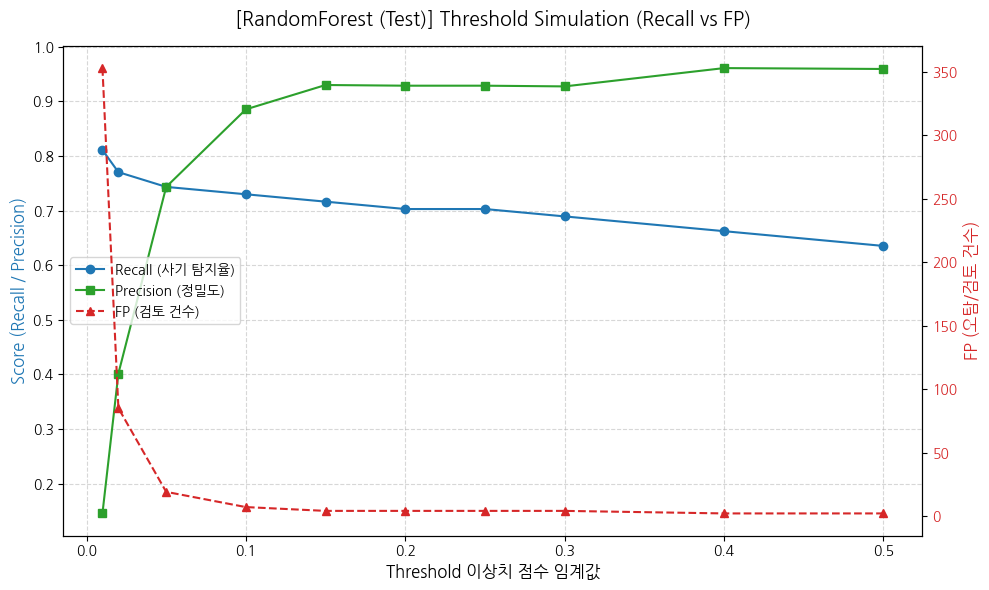

[저장 완료] 그래프 파일: /home/user1/study/credit-card-fds/reports/figures/randomforest_test_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.01,0.810811,0.145278,0.246407,60,353,14,413,RandomForest,test
1,0.02,0.770270,0.401408,0.527778,57,85,17,142,RandomForest,test
2,0.05,0.743243,0.743243,0.743243,55,19,19,74,RandomForest,test
3,0.10,0.729730,0.885246,0.800000,54,7,20,61,RandomForest,test
4,0.15,0.716216,0.929825,0.809160,53,4,21,57,RandomForest,test
5,0.20,0.702703,0.928571,0.800000,52,4,22,56,RandomForest,test
6,0.25,0.702703,0.928571,0.800000,52,4,22,56,RandomForest,test
7,0.30,0.689189,0.927273,0.790698,51,4,23,55,RandomForest,test
8,0.40,0.662162,0.960784,0.784000,49,2,25,51,RandomForest,test
9,0.50,0.635135,0.959184,0.764228,47,2,27,49,RandomForest,test


In [11]:
final_thresholds = [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

final_test_sim = evaluate_thresholds(y_test, test_probs[FINAL_MODEL_NAME], thresholds=final_thresholds)
final_test_sim["Model"] = FINAL_MODEL_NAME
final_test_sim["Split"] = "test"

plot_and_save_simulation(
    final_test_sim,
    model_name=f"{FINAL_MODEL_NAME} (Test)",
    filename=f"{FINAL_MODEL_NAME.lower()}_test_simulation.png",
    figures_dir=FIGURE_DIR,
)
display(final_test_sim)

## 5. SHAP — 사기 판단 근거 설명 (XAI)

- **대상 모델**: 검증 단계에서 선택된 최종 모델
- **설명 데이터**: Test Set의 사기 거래 전체 + 정상 거래 무작위 표본 (트리 SHAP 계산 시간을 줄이기 위함)
- SHAP 값 > 0 → 사기 확률을 **올린** 요인, < 0 → **낮춘** 요인

In [12]:
import shap

final_model = models[FINAL_MODEL_NAME]
final_th = SELECTED_THRESHOLDS[FINAL_MODEL_NAME]
final_prob = test_probs[FINAL_MODEL_NAME]

# 설명용 표본: 사기 전체 + 정상 1,000건
N_NORMAL_SAMPLE = 1000
fraud_idx = np.where(y_test == 1)[0]
normal_idx = np.random.default_rng(RANDOM_STATE).choice(
    np.where(y_test == 0)[0], size=N_NORMAL_SAMPLE, replace=False
)
shap_idx = np.sort(np.concatenate([fraud_idx, normal_idx]))
X_shap = X_test.iloc[shap_idx]

explainer = shap.TreeExplainer(final_model)
shap_raw = explainer(X_shap)

# 랜덤포레스트는 클래스별(정상/사기) SHAP을 반환하므로 사기(1) 클래스만 사용
shap_values = shap_raw[:, :, 1] if shap_raw.values.ndim == 3 else shap_raw

print(f"SHAP 계산 완료: {X_shap.shape[0]:,}건 (사기 {len(fraud_idx)} + 정상 {N_NORMAL_SAMPLE})")
print("SHAP 값 shape:", shap_values.values.shape)

/home/user1/anaconda3/envs/dkenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP 계산 완료: 1,074건 (사기 74 + 정상 1000)
SHAP 값 shape: (1074, 30)


### 5.1 전역 설명 — 어떤 변수가 사기 판단에 가장 크게 작용하는가

,Feature,Mean_Abs_SHAP,Mean_Abs_SHAP_Fraud
0,V14,0.0751,0.0999
1,V12,0.0719,0.0616
2,V10,0.0634,0.0925
3,V4,0.0525,0.0516
4,V3,0.0457,0.0347
5,V11,0.0421,0.0491
6,V17,0.0303,0.0579
7,V16,0.0173,0.0215
8,V7,0.0145,0.0273
9,V9,0.0103,0.0105


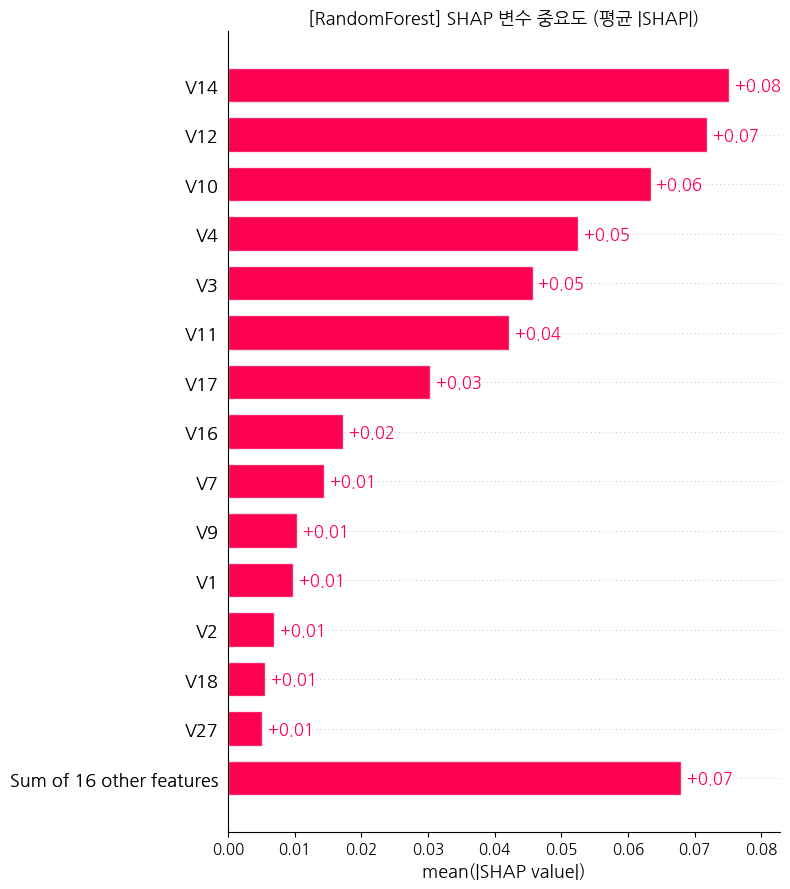

In [13]:
# 변수별 평균 |SHAP| 중요도
shap_importance = (
    pd.DataFrame({
        "Feature": X_shap.columns,
        "Mean_Abs_SHAP": np.abs(shap_values.values).mean(axis=0),
        # 사기 거래만 대상으로 한 중요도 (사기 판단에 실제로 쓰인 근거)
        "Mean_Abs_SHAP_Fraud": np.abs(shap_values.values[y_test[shap_idx] == 1]).mean(axis=0),
    })
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)
display(shap_importance.head(10).round(4))

plt.figure()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title(f"[{FINAL_MODEL_NAME}] SHAP 변수 중요도 (평균 |SHAP|)", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "shap_importance_bar.png", dpi=300, bbox_inches="tight")
plt.show()

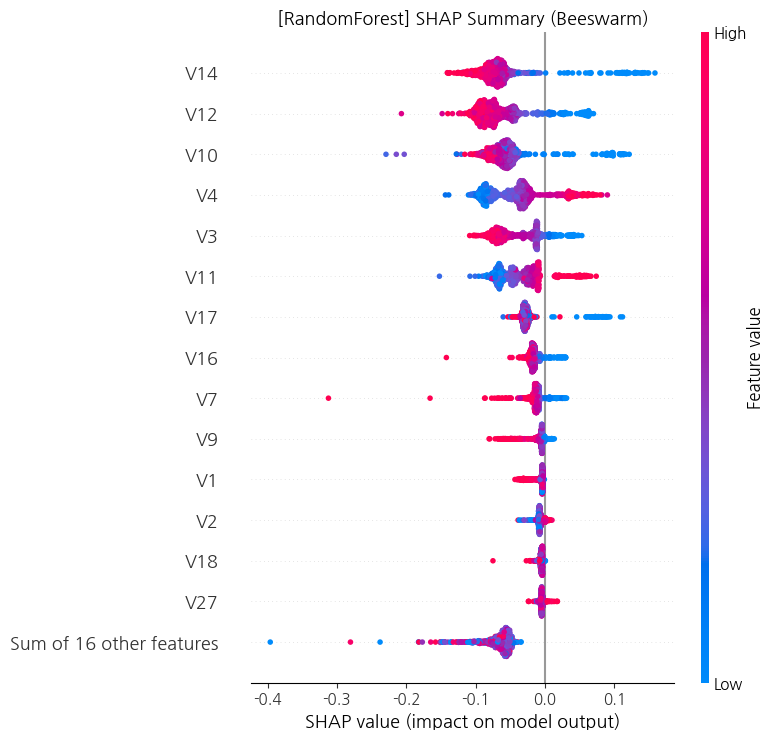

In [14]:
# Beeswarm: 각 점 = 거래 1건, 색 = 변수 값(빨강 높음/파랑 낮음), 가로 위치 = 사기 확률에 준 영향
plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"[{FINAL_MODEL_NAME}] SHAP Summary (Beeswarm)", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "shap_summary_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

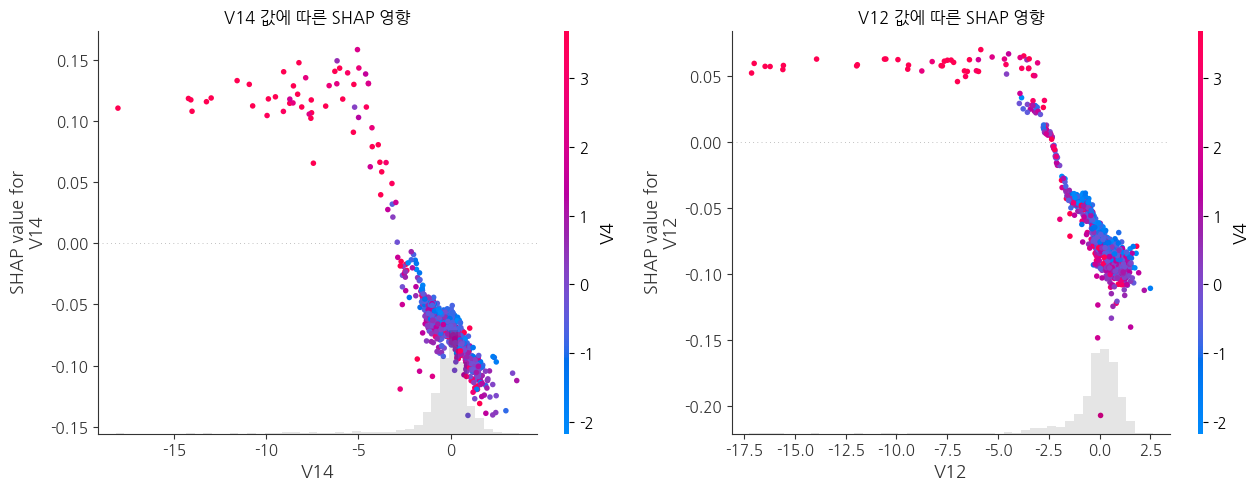

In [15]:
# 상위 2개 변수의 값 변화에 따른 SHAP 영향 (Dependence)
top_features = shap_importance["Feature"].head(2).tolist()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, feat in zip(axes, top_features):
    shap.plots.scatter(shap_values[:, feat], color=shap_values, ax=ax, show=False)
    ax.set_title(f"{feat} 값에 따른 SHAP 영향")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "shap_dependence_top2.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.2 개별 거래 설명 — 상담원 관점

운영 임계값 기준으로 세 가지 대표 사례를 설명합니다.
- **TP (탐지 성공)**: 사기 확률이 가장 높았던 실제 사기 거래 — "왜 차단되었나"
- **FN (놓친 사기)**: 실제 사기지만 임계값 아래로 판단된 거래 중 임계값에 가장 가까웠던 거래 — "왜 놓쳤나"
- **FP (오탐)**: 정상 거래인데 사기로 경고된 거래 — "왜 오해했나"

[TP (탐지 성공)] Test 행 번호 8962 | 사기 확률 0.9950 (임계값 0.05)


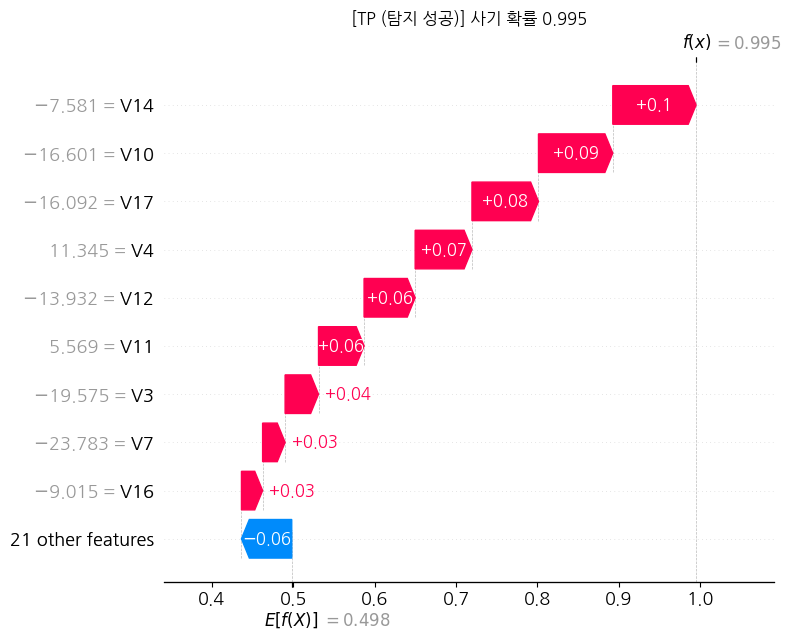

[FN (놓친 사기)] Test 행 번호 894 | 사기 확률 0.0300 (임계값 0.05)


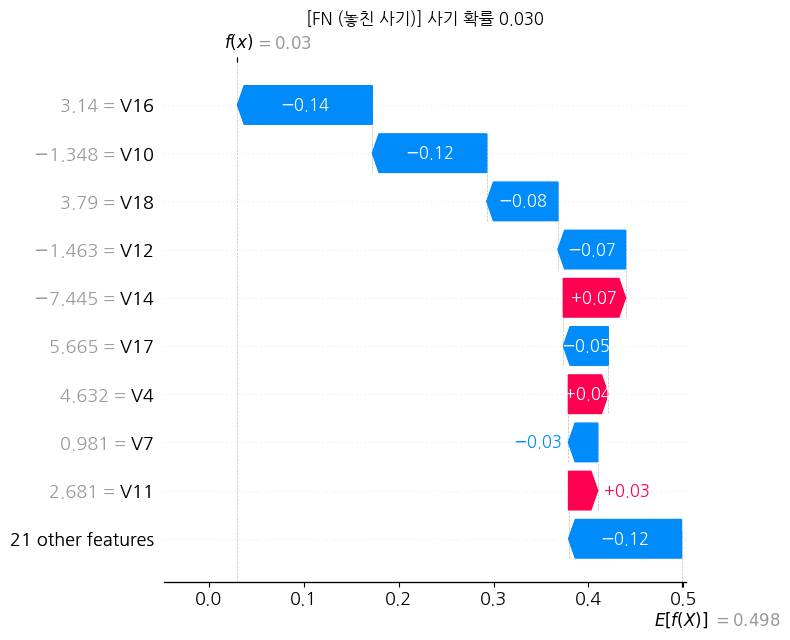

[FP (오탐)] Test 행 번호 23768 | 사기 확률 0.9450 (임계값 0.05)


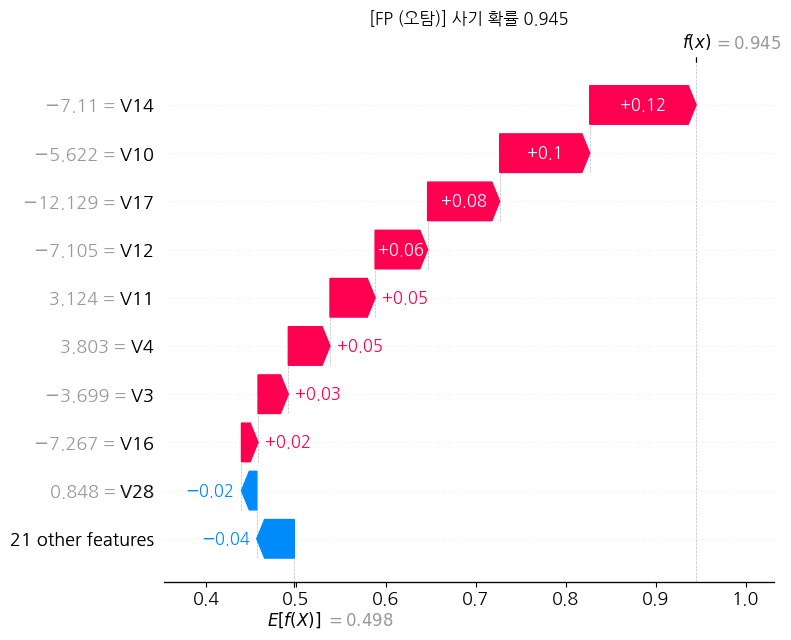

In [16]:
# 사례는 Test 전체에서 선택 (오탐 거래는 무작위 정상 표본에 거의 포함되지 않기 때문)
test_pred = (final_prob >= final_th).astype(int)

def pick_case(mask):
    """조건을 만족하는 거래 중 사기 확률이 가장 높은 1건의 Test 행 번호 반환"""
    rows = np.where(mask)[0]
    return rows[np.argmax(final_prob[rows])] if len(rows) else None

cases = {
    "TP (탐지 성공)": pick_case((y_test == 1) & (test_pred == 1)),   # 가장 확신한 탐지
    "FN (놓친 사기)": pick_case((y_test == 1) & (test_pred == 0)),   # 임계값에 가장 가까웠던 미탐
    "FP (오탐)": pick_case((y_test == 0) & (test_pred == 1)),        # 가장 강하게 오해한 정상 거래
}

for label, row in cases.items():
    if row is None:
        print(f"[{label}] 해당 사례가 없습니다.")
        continue

    print(f"[{label}] Test 행 번호 {row} | 사기 확률 {final_prob[row]:.4f} (임계값 {final_th})")
    case_raw = explainer(X_test.iloc[[row]])
    case_shap = case_raw[0, :, 1] if case_raw.values.ndim == 3 else case_raw[0]

    plt.figure()
    shap.plots.waterfall(case_shap, max_display=10, show=False)
    plt.title(f"[{label}] 사기 확률 {final_prob[row]:.3f}", fontsize=12)
    plt.tight_layout()
    fname = "shap_waterfall_" + label.split()[0].lower() + ".png"
    plt.savefig(FIGURE_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()

## 6. 결과 저장

In [17]:
test_results_df.to_csv(TABLE_DIR / "final_test_metrics.csv", index=False, encoding="utf-8-sig")
cost_df.to_csv(TABLE_DIR / "final_test_cost.csv", index=False, encoding="utf-8-sig")
final_test_sim.to_csv(TABLE_DIR / "final_test_thresholds.csv", index=False, encoding="utf-8-sig")
shap_importance.to_csv(TABLE_DIR / "final_test_shap_importance.csv", index=False, encoding="utf-8-sig")

for name in ["final_test_metrics.csv", "final_test_cost.csv",
             "final_test_thresholds.csv", "final_test_shap_importance.csv"]:
    print(f"[저장] {TABLE_DIR / name}")

for png in sorted(FIGURE_DIR.glob("*test*.png")) + sorted(FIGURE_DIR.glob("shap_*.png")):
    print(f"[그래프] {png.name}")

[저장] /home/user1/study/credit-card-fds/reports/tables/final_test_metrics.csv
[저장] /home/user1/study/credit-card-fds/reports/tables/final_test_cost.csv
[저장] /home/user1/study/credit-card-fds/reports/tables/final_test_thresholds.csv
[저장] /home/user1/study/credit-card-fds/reports/tables/final_test_shap_importance.csv
[그래프] randomforest_test_simulation.png
[그래프] test_confusion_matrix.png
[그래프] test_pr_curve.png
[그래프] shap_dependence_top2.png
[그래프] shap_importance_bar.png
[그래프] shap_summary_beeswarm.png
[그래프] shap_waterfall_fn.png
[그래프] shap_waterfall_fp.png
[그래프] shap_waterfall_tp.png


## 7. 결론 요약 (자동 생성)

In [18]:
final_row = val_vs_test[val_vs_test["Model"] == FINAL_MODEL_NAME].iloc[0]
final_cost = cost_df[(cost_df["Model"] == FINAL_MODEL_NAME) & np.isclose(cost_df["Threshold"], final_th)].iloc[0]
lr_ap = test_results_df.loc[test_results_df["Model"] == "LogisticRegression", "PR_AUC"].iloc[0]

print(f"■ 최종 모델: {FINAL_MODEL_NAME} (운영 임계값 {final_th}, 검증 단계에서 확정)")
print(f"■ Test PR-AUC: {final_row['Test_PR_AUC']:.4f}  (베이스라인 로지스틱 회귀 {lr_ap:.4f})")
print(f"■ Test Recall: {final_row['Test_Recall']:.4f} (검증 {final_row['Val_Recall']:.4f}) → 목표 0.80 {'달성' if final_row['Test_Recall'] >= 0.80 else '미달'}")
print(f"■ Test Precision: {final_row['Test_Precision']:.4f} (검증 {final_row['Val_Precision']:.4f})")
print(f"■ 검토 건수: Test {int(final_row['Test_Flagged'])}건 → 하루 약 {final_cost['Daily_Flagged_Est']}건 추정")
print(f"■ 총 손실 비용(가정): Test {final_cost['Total_Cost']:,.0f} EUR → 하루 약 {final_cost['Daily_Cost_Est']:,.0f} EUR")
print(f"■ SHAP 상위 변수: {', '.join(shap_importance['Feature'].head(5))}")

■ 최종 모델: RandomForest (운영 임계값 0.05, 검증 단계에서 확정)
■ Test PR-AUC: 0.7364  (베이스라인 로지스틱 회귀 0.6803)
■ Test Recall: 0.7432 (검증 0.8649) → 목표 0.80 미달
■ Test Precision: 0.7432 (검증 0.7111)
■ 검토 건수: Test 74건 → 하루 약 247건 추정
■ 총 손실 비용(가정): Test 2,413 EUR → 하루 약 8,043 EUR
■ SHAP 상위 변수: V14, V12, V10, V4, V3
